# Plant Disease Domain Gap: Baseline Reproduction and Midterm Experiments

This notebook continues `Plant_Disease_Domain_Gap.ipynb`. It runs in Google Colab or locally.

1. **Data preparation.** Rebuilds the same 12-class pilot, SHA-256 audit and seed-42 source split (9,796 / 1,729).
2. **Baseline reproduction (B0).** Frozen ImageNet ResNet-18 with a new 12-class head, trained for 3 epochs on CPU. It uses the same settings and random-seed order as the original notebook.
3. **E1: longer training.** The same frozen model is trained for 30 epochs. The checkpoint is selected by PlantVillage validation macro-F1.
4. **E2: augmentation baseline.** The frozen backbone is kept. The head is trained on augmented PlantVillage images and selected by PlantVillage validation macro-F1.
5. **E3: limited-field fine-tuning.** The PlantDoc *training* images are audited for exact and near duplicates of PlantDoc test. They are split into adaptation and validation subsets. The model is fine-tuned on 10/25/50/100% of the adaptation subset, with 3 seeds each, and selected by PlantDoc validation macro-F1.
6. **Held-out evaluation.** PlantDoc test is used only for the final evaluation of each selected checkpoint. It is reported with bootstrap 95% confidence intervals.

Team: Muskan Ejaz, Juwairiya Haroon, Zainab Hashmi.

In [1]:
import os, sys, time, json, copy, random
from pathlib import Path
from collections import Counter, defaultdict
from hashlib import sha256

import numpy as np
import pandas as pd
from PIL import Image

IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content") if IN_COLAB else Path(os.environ.get("PDG_ROOT", Path.cwd().parent / "data")).resolve()
OUT = (Path("/content/outputs") if IN_COLAB else Path.cwd() / "outputs")
OUT.mkdir(parents=True, exist_ok=True)
SMOKE = os.environ.get("PDG_SMOKE") == "1"   # quick code check on a small subset
print("Data folder:", ROOT)
print("Output folder:", OUT)
print("Smoke test:", SMOKE)

Data folder: ~/Desktop/Plant_Disease_Domain_Gap/data
Output folder: ~/Desktop/Plant_Disease_Domain_Gap/repo/outputs
Smoke test: False


## 1. Data download (skipped if the files already exist)

In [2]:
import subprocess
from huggingface_hub import hf_hub_download

plantdoc_path = ROOT / "PlantDoc"
if not (plantdoc_path / "test").is_dir():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/pratikkayal/PlantDoc-Dataset.git", str(plantdoc_path)], check=True)

pv_files = {}
for name in ("splits/color_train.txt", "splits/color_test.txt", "data.zip"):
    pv_files[name] = hf_hub_download(repo_id="mohanty/PlantVillage", repo_type="dataset",
                                     filename=name, local_dir=ROOT / "PlantVillage_hf")
print("PlantDoc and PlantVillage files are available.")

~/Desktop/cv/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PlantDoc and PlantVillage files are available.


## 2. Same class mapping, pilot selection and audit as the baseline notebook

In [3]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(folder):
    return sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in image_extensions)

plantdoc_counts = pd.DataFrame({
    split: {f.name: len(list_images(f)) for f in (plantdoc_path / split).iterdir()
            if f.is_dir() and not f.name.startswith(".")}
    for split in ("train", "test")
}).fillna(0).astype(int).sort_index()

color_lists = {split: [l.strip() for l in Path(pv_files[f"splits/color_{split}.txt"]).read_text().splitlines() if l.strip()]
               for split in ("train", "test")}

class_map = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "grape leaf black rot": "Grape___Black_rot",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
}
pv_counts = {split: Counter(Path(p).parent.name for p in paths) for split, paths in color_lists.items()}
for doc_label, village_label in class_map.items():
    assert plantdoc_counts.loc[doc_label, "test"] > 0
    assert pv_counts["train"][village_label] > 0 and pv_counts["test"][village_label] > 0

mapping_table = pd.DataFrame({
    "PlantVillage class": pd.Series(class_map),
    "PlantVillage train list": [pv_counts["train"][v] for v in class_map.values()],
    "PlantVillage test": [pv_counts["test"][v] for v in class_map.values()],
    "PlantDoc train": [plantdoc_counts.loc[d, "train"] for d in class_map],
    "PlantDoc test": [plantdoc_counts.loc[d, "test"] for d in class_map],
})
mapping_table.index.name = "PlantDoc class"
mapping_table.to_csv(OUT / "class_mapping_counts.csv")
display(mapping_table)
print("PlantDoc test images in the pilot:", mapping_table["PlantDoc test"].sum())

,PlantVillage class,PlantVillage train list,PlantVillage test,PlantDoc train,PlantDoc test
PlantDoc class,,,,,
Apple Scab Leaf,Apple___Apple_scab,503,127,83,10
Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,406,107,64,4
Potato leaf early blight,Potato___Early_blight,836,164,109,8
Potato leaf late blight,Potato___Late_blight,788,212,97,8
Squash Powdery mildew leaf,Squash___Powdery_mildew,1457,378,124,6
grape leaf black rot,Grape___Black_rot,1012,168,56,8
Tomato Early blight leaf,Tomato___Early_blight,785,215,79,9
Tomato Septoria leaf spot,Tomato___Septoria_leaf_spot,1434,337,140,11
Tomato leaf bacterial spot,Tomato___Bacterial_spot,1691,436,101,9


PlantDoc test images in the pilot: 99


In [4]:
from zipfile import ZipFile

pilot_classes = set(class_map.values())
pilot_paths = {split: [p for p in paths if Path(p).parent.name in pilot_classes]
               for split, paths in color_lists.items()}
pv_image_root = ROOT / "PlantVillage_pilot"

if not (pv_image_root / "done.txt").exists():
    with ZipFile(pv_files["data.zip"]) as archive:
        color_members = {m[m.index("raw/color/"):]: m for m in archive.namelist()
                         if "raw/color/" in m and not m.endswith("/")}
        for split, paths in pilot_paths.items():
            for path in paths:
                rel = path.removeprefix("./")
                target = pv_image_root / split / rel
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(color_members[rel]))
    (pv_image_root / "done.txt").write_text("ok")
for split in pilot_paths:
    print(f"PlantVillage {split}: {len(pilot_paths[split]):,} pilot images")

PlantVillage train: 11,533 pilot images
PlantVillage test: 2,757 pilot images


In [5]:
def audit_images(paths):
    hashes, unreadable = defaultdict(list), []
    for path in paths:
        try:
            with Image.open(path) as image:
                image.load()
            hashes[sha256(path.read_bytes()).hexdigest()].append(path)
        except (OSError, ValueError):
            unreadable.append(path)
    return hashes, unreadable

audit_paths = {
    "PlantVillage train": [pv_image_root / "train" / p for p in pilot_paths["train"]],
    "PlantVillage test": [pv_image_root / "test" / p for p in pilot_paths["test"]],
    "PlantDoc test": [p for label in class_map for p in list_images(plantdoc_path / "test" / label)],
    "PlantDoc train": [p for label in class_map for p in list_images(plantdoc_path / "train" / label)],
}
image_audits = {}
for name, paths in audit_paths.items():
    image_audits[name] = audit_images(paths)
    print(f"{name}: {len(paths):,} files, {len(image_audits[name][1])} unreadable")

PlantVillage train: 11,533 files, 0 unreadable


PlantVillage test: 2,757 files, 0 unreadable


PlantDoc test: 99 files, 0 unreadable


PlantDoc train: 1,083 files, 0 unreadable


In [6]:
source_hashes = image_audits["PlantVillage train"][0]
lab_test_hashes = set(image_audits["PlantVillage test"][0])
field_test_hashes = set(image_audits["PlantDoc test"][0])
test_hashes = lab_test_hashes | field_test_hashes
print("PlantVillage test hashes shared with train:", len(source_hashes.keys() & lab_test_hashes))
print("PlantDoc test hashes shared with train:", len(source_hashes.keys() & field_test_hashes))

clean_source_hashes = {h: p for h, p in source_hashes.items() if h not in test_hashes}
clean_count = sum(len(p) for p in clean_source_hashes.values())
source_rows = []
for fingerprint, paths in sorted(clean_source_hashes.items()):
    labels = {p.parent.name for p in paths}
    assert len(labels) == 1
    source_rows.append({"path": min(paths), "label": labels.pop(), "hash": fingerprint})
source_data = pd.DataFrame(source_rows)
print("Training files excluded (match a test image):", len(audit_paths["PlantVillage train"]) - clean_count)
print("Extra copies excluded inside the source pool:", clean_count - len(source_data))

from sklearn.model_selection import train_test_split
train_data, val_data = train_test_split(source_data, test_size=0.15, random_state=42,
                                        stratify=source_data["label"])
print("Training images:", len(train_data), " Validation images:", len(val_data))
assert SMOKE or (len(train_data), len(val_data)) == (9796, 1729), "Split differs from the baseline notebook"

PlantVillage test hashes shared with train: 3
PlantDoc test hashes shared with train: 0
Training files excluded (match a test image): 3
Extra copies excluded inside the source pool: 5


Training images: 9796  Validation images: 1729


## 3. Audit of PlantDoc training images before field adaptation

SHA-256 only finds byte-identical files. We also compute a 64-bit difference hash (dHash) of every PlantDoc image. Any PlantDoc training image within Hamming distance 6 of a PlantDoc test image is treated as a near duplicate and left out of adaptation, so the field test set stays unseen.

In [7]:
def dhash(path, size=8):
    with Image.open(path) as im:
        g = im.convert("L").resize((size + 1, size), Image.BILINEAR)
    px = np.asarray(g, dtype=np.int16)
    bits = (px[:, 1:] > px[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)

hamming = lambda a, b: bin(a ^ b).count("1")
NEAR_DUP_THRESHOLD = 6

pd_test_paths = audit_paths["PlantDoc test"]
pd_train_hashes = image_audits["PlantDoc train"][0]
test_dh = {p: dhash(p) for p in pd_test_paths}

field_rows, near_pairs, exact_pairs = [], [], 0
seen = set()
for fingerprint, paths in sorted(pd_train_hashes.items()):
    path = min(paths)
    labels = {p.parent.name for p in paths}
    if fingerprint in test_hashes or fingerprint in source_hashes:
        exact_pairs += 1
        continue
    if len(labels) != 1:
        continue
    d = dhash(path)
    close = [(t, hamming(d, td)) for t, td in test_dh.items() if hamming(d, td) <= NEAR_DUP_THRESHOLD]
    if close:
        near_pairs += [(path, t, dist) for t, dist in close]
        continue
    field_rows.append({"path": path, "label": class_map[labels.pop()], "hash": fingerprint})

field_pool = pd.DataFrame(field_rows)
n_train_files = len(audit_paths["PlantDoc train"])
n_unique = len(pd_train_hashes)
n_near_files = len({p for p, _, _ in near_pairs})
print(f"PlantDoc train files in the 12 classes: {n_train_files}")
print(f"Exact copies inside PlantDoc train removed: {n_train_files - n_unique - len(image_audits['PlantDoc train'][1])}")
print(f"Byte-identical to a test or source image: {exact_pairs}")
print(f"Near duplicates of a PlantDoc test image (dHash <= {NEAR_DUP_THRESHOLD}): {n_near_files} files, {len(near_pairs)} pairs")
print(f"Field pool kept for adaptation: {len(field_pool)}")

field_adapt, field_val = train_test_split(field_pool, test_size=0.2, random_state=42, stratify=field_pool["label"])
print("Field adaptation images:", len(field_adapt), " Field validation images:", len(field_val))
pd.DataFrame(near_pairs, columns=["plantdoc_train", "plantdoc_test", "dhash_distance"]).to_csv(OUT / "near_duplicates.csv", index=False)

PlantDoc train files in the 12 classes: 1083
Exact copies inside PlantDoc train removed: 1
Byte-identical to a test or source image: 6
Near duplicates of a PlantDoc test image (dHash <= 6): 4 files, 4 pairs
Field pool kept for adaptation: 1071
Field adaptation images: 856  Field validation images: 215


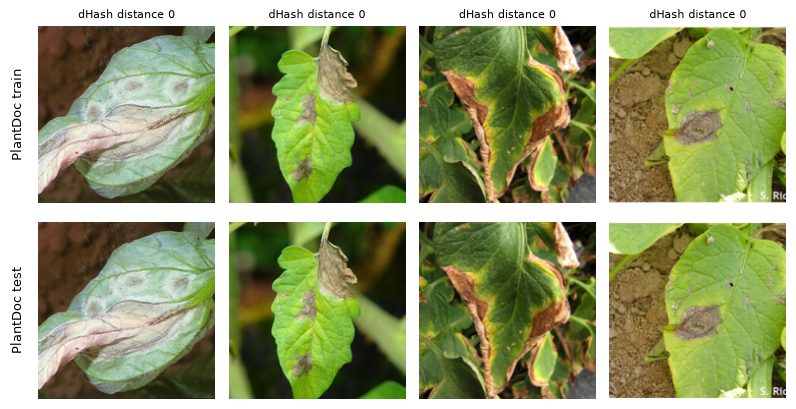

In [8]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 10})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

def thumb(path, size=180):
    with Image.open(path) as im:
        im = im.convert("RGB")
        w, h = im.size; s = min(w, h)
        return im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((size, size))

if near_pairs:
    show = sorted(near_pairs, key=lambda r: r[2])[:6]
    fig, axes = plt.subplots(2, len(show), figsize=(2.0 * len(show), 4.3))
    axes = np.array(axes).reshape(2, -1)
    for j, (a, b, dist) in enumerate(show):
        axes[0, j].imshow(thumb(a)); axes[1, j].imshow(thumb(b))
        axes[0, j].set_title(f"dHash distance {dist}", fontsize=8)
        for ax in axes[:, j]: ax.axis("off")
    axes[0, 0].text(-0.08, 0.5, "PlantDoc train", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
    axes[1, 0].text(-0.08, 0.5, "PlantDoc test", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
    plt.tight_layout(); fig.savefig(OUT / "fig_near_duplicates.png", dpi=200, bbox_inches="tight"); plt.show()

In [9]:
split_table = pd.DataFrame({
    "Source train": train_data["label"].value_counts(),
    "Source val": val_data["label"].value_counts(),
    "PlantVillage test": pd.Series([Path(p).parent.name for p in pilot_paths["test"]]).value_counts(),
    "Field adapt": field_adapt["label"].value_counts(),
    "Field val": field_val["label"].value_counts(),
    "PlantDoc test": pd.Series([class_map[p.parent.name] for p in pd_test_paths]).value_counts(),
}).fillna(0).astype(int).sort_index()
split_table.loc["Total"] = split_table.sum()
split_table.to_csv(OUT / "split_counts.csv")
display(split_table)

,Source train,Source val,PlantVillage test,Field adapt,Field val,PlantDoc test
Apple___Apple_scab,428,75,127,66,17,10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,345,61,107,51,13,4
Grape___Black_rot,860,152,168,45,11,8
Potato___Early_blight,711,125,164,84,21,8
Potato___Late_blight,670,118,212,76,19,8
Squash___Powdery_mildew,1238,219,378,99,25,6
Tomato___Bacterial_spot,1437,254,436,80,20,9
Tomato___Early_blight,667,118,215,63,15,9
Tomato___Late_blight,1297,229,375,79,20,10
Tomato___Leaf_Mold,663,117,172,68,17,6


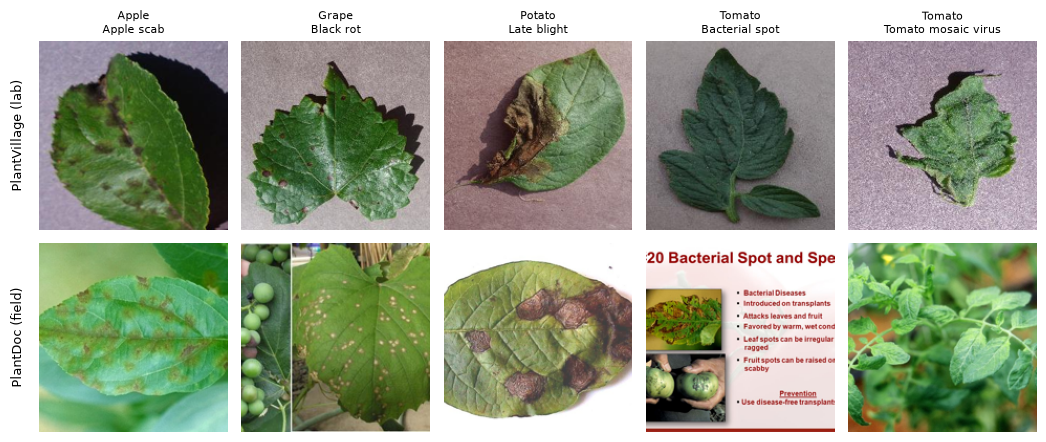

In [10]:
# example images: same disease, lab vs field
examples = ["Apple___Apple_scab", "Grape___Black_rot", "Potato___Late_blight", "Tomato___Bacterial_spot", "Tomato___Tomato_mosaic_virus"]
doc_label_by_class = {v: k for k, v in class_map.items()}
fig, axes = plt.subplots(2, len(examples), figsize=(2.1 * len(examples), 4.6))
for j, cls in enumerate(examples):
    pv = sorted(p for p in audit_paths["PlantVillage test"] if p.parent.name == cls)[0]
    fd = sorted(p for p in pd_test_paths if p.parent.name == doc_label_by_class[cls])[0]
    axes[0, j].imshow(thumb(pv)); axes[1, j].imshow(thumb(fd))
    axes[0, j].set_title(cls.split("___")[0] + "\n" + cls.split("___")[1].replace("_", " "), fontsize=8)
    for ax in axes[:, j]: ax.axis("off")
axes[0, 0].text(-0.08, 0.5, "PlantVillage (lab)", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.08, 0.5, "PlantDoc (field)", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); fig.savefig(OUT / "fig_domain_examples.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. B0: baseline reproduction (same code path and random-seed order as the original notebook, on CPU)

In [11]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
import torchvision.transforms as T
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support

if SMOKE:
    train_data = train_data.groupby("label").head(12); val_data = val_data.groupby("label").head(6)
    field_adapt = field_adapt.groupby("label").head(6); field_val = field_val.groupby("label").head(3)

torch.manual_seed(42)
cpu = torch.device("cpu")
fast = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
NUM_WORKERS = 2 if IN_COLAB else 0
class_names = sorted(class_map.values())
label_to_id = {label: i for i, label in enumerate(class_names)}
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
print("Baseline device: cpu | experiment device:", fast)

class LeafDataset(Dataset):
    def __init__(self, rows, transform=preprocess, cache=None):
        self.samples = list(zip(rows["path"], rows["label"]))
        self.transform, self.cache = transform, cache
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, index):
        path, label = self.samples[index]
        if self.cache is not None and path in self.cache:
            image = self.cache[path]
        else:
            with Image.open(path) as im:
                image = im.convert("RGB")
        return self.transform(image), label_to_id[label]

train_loader = DataLoader(LeafDataset(train_data), batch_size=32, shuffle=True)
val_loader = DataLoader(LeafDataset(val_data), batch_size=32)
images, labels = next(iter(train_loader))          # the original notebook draws one batch here
print("Image batch shape:", tuple(images.shape))

model = resnet18(weights=weights)
model.requires_grad_(False)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

def train_one_epoch():
    model.eval(); model.fc.train()
    total = 0.0
    for x, y in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward(); optimizer.step()
        total += loss.item() * len(y)
    return total / len(train_loader.dataset)

@torch.inference_mode()
def validation_f1():
    model.eval(); actual, predicted = [], []
    for x, y in val_loader:
        actual += y.tolist(); predicted += model(x).argmax(1).tolist()
    return f1_score(actual, predicted, average="macro", zero_division=0)

best_f1, b0_log, t0 = -1.0, [], time.time()
for epoch in range(1, 4):
    train_loss = train_one_epoch(); val_f1 = validation_f1()
    b0_log.append({"epoch": epoch, "train_loss": train_loss, "val_macro_f1": val_f1})
    print(f"Epoch {epoch} | Train loss {train_loss:.4f} | Val macro-F1 {val_f1:.4f} | {time.time() - t0:.0f}s")
    if val_f1 > best_f1:
        best_f1 = val_f1
        b0_state = copy.deepcopy(model.state_dict()); b0_epoch = epoch
torch.save({"model_state": b0_state, "class_names": class_names, "epoch": b0_epoch, "val_macro_f1": best_f1},
           OUT / "resnet18_baseline_repro.pt")
pd.DataFrame(b0_log).to_csv(OUT / "b0_epoch_log.csv", index=False)
print(f"Best epoch {b0_epoch}, validation macro-F1 {best_f1:.4f}")

Baseline device: cpu | experiment device: mps
Image batch shape: (32, 3, 224, 224)


Epoch 1 | Train loss 0.7818 | Val macro-F1 0.8659 | 178s


Epoch 2 | Train loss 0.3228 | Val macro-F1 0.9037 | 358s


Epoch 3 | Train loss 0.2458 | Val macro-F1 0.9241 | 540s
Best epoch 3, validation macro-F1 0.9241


## 5. Cached features for the frozen backbone

With the backbone frozen in evaluation mode and the preprocessing fixed, every image always produces the same 512-d feature vector. We compute these once and reuse them to train and evaluate linear heads (E1) and to evaluate every frozen-backbone model.

In [12]:
def resized_cache(rows_or_paths, short=256):
    """Field images are large; resize once to a 256-pixel short side (what the preprocessing does anyway)."""
    cache = {}
    for p in rows_or_paths:
        with Image.open(p) as im:
            im = im.convert("RGB")
            w, h = im.size; s = short / min(w, h)
            cache[p] = im.resize((max(short, round(w * s)), max(short, round(h * s))), Image.BILINEAR) if min(w, h) > short else im.copy()
    return cache

field_cache = resized_cache(list(field_adapt["path"]) + list(field_val["path"]) + list(pd_test_paths))

test_frames = {
    "PlantVillage test": pd.DataFrame({"path": sorted(audit_paths["PlantVillage test"]),
                                       "label": [p.parent.name for p in sorted(audit_paths["PlantVillage test"])]}),
    "PlantDoc test": pd.DataFrame({"path": sorted(pd_test_paths),
                                   "label": [class_map[p.parent.name] for p in sorted(pd_test_paths)]}),
}
if SMOKE:
    test_frames["PlantVillage test"] = test_frames["PlantVillage test"].groupby("label").head(10)

def backbone_from(state=None):
    m = resnet18(weights=weights)
    m.fc = nn.Linear(512, len(class_names))
    if state is not None:
        m.load_state_dict(state)
    m.requires_grad_(False)
    return m

@torch.inference_mode()
def extract(rows, device=fast):
    m = backbone_from().to(device).eval(); m.fc = nn.Identity()
    loader = DataLoader(LeafDataset(rows, cache=field_cache), batch_size=64, num_workers=NUM_WORKERS)
    feats, ys = [], []
    for x, y in loader:
        feats.append(m(x.to(device)).float().cpu()); ys.append(y)
    return torch.cat(feats), torch.cat(ys)

t0 = time.time()
features = {name: extract(rows) for name, rows in [("source_train", train_data), ("source_val", val_data),
            ("pv_test", test_frames["PlantVillage test"]), ("pd_test", test_frames["PlantDoc test"]),
            ("field_adapt", field_adapt), ("field_val", field_val)]}
print({k: tuple(v[0].shape) for k, v in features.items()}, f"{time.time() - t0:.0f}s")

{'source_train': (9796, 512), 'source_val': (1729, 512), 'pv_test': (2757, 512), 'pd_test': (99, 512), 'field_adapt': (856, 512), 'field_val': (215, 512)} 47s


In [13]:
def scores_from_logits(logits, y):
    pred = logits.argmax(1).numpy(); y = y.numpy()
    return {"accuracy": 100 * accuracy_score(y, pred),
            "macro_f1": 100 * f1_score(y, pred, labels=range(len(class_names)), average="macro", zero_division=0)}, pred

@torch.inference_mode()
def eval_head(head, split):
    X, y = features[split]
    return scores_from_logits(head(X), y)

def bootstrap_ci(y, pred, n=2000, seed=0):
    rng = np.random.default_rng(seed); y, pred = np.asarray(y), np.asarray(pred)
    vals = [100 * f1_score(y[idx], pred[idx], labels=range(len(class_names)), average="macro", zero_division=0)
            for idx in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

# B0 is evaluated exactly like the original notebook: full model on CPU, original image files
b0_head = nn.Linear(512, len(class_names)); b0_head.load_state_dict({"weight": b0_state["fc.weight"], "bias": b0_state["fc.bias"]})
model.load_state_dict(b0_state); model.eval()
results, predictions = {}, {}
with torch.inference_mode():
    for name, rows in test_frames.items():
        logits, ys = [], []
        for x, y in DataLoader(LeafDataset(rows), batch_size=32):
            logits.append(model(x)); ys.append(y)
        s, pred = scores_from_logits(torch.cat(logits), torch.cat(ys))
        results[("B0", name)] = s; predictions[("B0", name)] = pred
b0_table = pd.DataFrame({name: results[("B0", name)] for name in test_frames}).T.round(2)
b0_table["Images"] = [len(rows) for rows in test_frames.values()]
b0_table.to_csv(OUT / "b0_repro_test_scores.csv")
display(b0_table)
print(f"B0 macro-F1 gap: {results[('B0', 'PlantVillage test')]['macro_f1'] - results[('B0', 'PlantDoc test')]['macro_f1']:.2f} pp")
# agreement between the CPU path and the cached-feature path used for the other frozen models
agree = (eval_head(b0_head, "pd_test")[1] == predictions[("B0", "PlantDoc test")]).mean()
print(f"Cached-feature predictions agree with the CPU path on {100 * agree:.1f}% of PlantDoc test images")

,accuracy,macro_f1,Images
PlantVillage test,92.46,92.08,2757
PlantDoc test,33.33,34.89,99


B0 macro-F1 gap: 57.19 pp
Cached-feature predictions agree with the CPU path on 96.0% of PlantDoc test images


## 6. E1: longer training of the frozen-backbone head (30 epochs, selected by PlantVillage validation macro-F1)

In [14]:
def train_linear_head(epochs, seed=42, lr=1e-3, batch=32):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    head = nn.Linear(512, len(class_names)); opt = torch.optim.Adam(head.parameters(), lr=lr)
    X, y = features["source_train"]; log, best = [], (-1, None, 0)
    for ep in range(1, epochs + 1):
        head.train(); perm = torch.randperm(len(y), generator=g); total = 0.0
        for i in range(0, len(y), batch):
            idx = perm[i:i + batch]; opt.zero_grad()
            loss = loss_fn(head(X[idx]), y[idx]); loss.backward(); opt.step(); total += loss.item() * len(idx)
        head.eval(); val = eval_head(head, "source_val")[0]["macro_f1"]
        log.append({"epoch": ep, "train_loss": total / len(y), "val_macro_f1": val})
        if val > best[0]: best = (val, copy.deepcopy(head.state_dict()), ep)
    head.load_state_dict(best[1])
    return head, pd.DataFrame(log), best[2]

e1_head, e1_log, e1_epoch = train_linear_head(5 if SMOKE else 30)
e1_log.to_csv(OUT / "e1_epoch_log.csv", index=False)
print(e1_log.round(4).to_string(index=False))
print("E1 selected epoch:", e1_epoch)
for split, name in [("pv_test", "PlantVillage test"), ("pd_test", "PlantDoc test")]:
    s, pred = eval_head(e1_head, split); results[("E1", name)] = s; predictions[("E1", name)] = pred

 epoch  train_loss  val_macro_f1
     1      0.7790       87.5842
     2      0.3228       91.3801
     3      0.2461       92.2401
     4      0.2066       92.9234
     5      0.1788       92.2139
     6      0.1612       92.7468
     7      0.1500       93.5784
     8      0.1358       92.7111
     9      0.1281       93.2989
    10      0.1194       93.4645
    11      0.1094       93.4420
    12      0.1050       93.7657
    13      0.1016       93.1084
    14      0.0968       93.8755
    15      0.0928       93.4216
    16      0.0859       93.2961
    17      0.0850       93.9781
    18      0.0816       94.1105
    19      0.0791       93.4608
    20      0.0741       93.5310
    21      0.0736       93.7939
    22      0.0701       93.0674
    23      0.0668       92.9791
    24      0.0652       93.7964
    25      0.0622       93.9986
    26      0.0609       94.3903
    27      0.0597       94.1784
    28      0.0583       94.1440
    29      0.0557       93.7841
    30    

## 7. E2: augmentation baseline (frozen backbone, augmented PlantVillage training images)

The augmentations imitate some field conditions: random crops and zoom (framing), flips and rotation (leaf pose), colour jitter (lighting), and blur (focus). Model selection uses unaugmented PlantVillage validation images only.

In [15]:
augment = T.Compose([
    T.RandomResizedCrop(224, scale=(0.35, 1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(25),
    T.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.05),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3),
    T.ToTensor(), T.Normalize(weights.transforms().mean, weights.transforms().std),
])

def train_head_augmented(rows, init_head, val_split, epochs, seed, lr=1e-3):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    net = backbone_from().to(fast).eval(); net.fc = nn.Identity()
    head = copy.deepcopy(init_head).to(fast) if init_head is not None else nn.Linear(512, len(class_names)).to(fast)
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    loader = DataLoader(LeafDataset(rows, transform=augment, cache=field_cache), batch_size=32, shuffle=True,
                        num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(seed))
    log, best = [], (-1, None, 0)
    for ep in range(1, epochs + 1):
        head.train(); total = 0.0
        for x, y in loader:
            with torch.no_grad():
                f = net(x.to(fast))
            opt.zero_grad(); loss = loss_fn(head(f), y.to(fast)); loss.backward(); opt.step(); total += loss.item() * len(y)
        cpu_head = copy.deepcopy(head).cpu().eval()
        val = eval_head(cpu_head, val_split)[0]["macro_f1"]
        log.append({"epoch": ep, "train_loss": total / len(rows), "val_macro_f1": val})
        if val > best[0]: best = (val, cpu_head.state_dict(), ep)
    out = nn.Linear(512, len(class_names)); out.load_state_dict(best[1])
    return out, pd.DataFrame(log), best[2]

t0 = time.time()
e2_head, e2_log, e2_epoch = train_head_augmented(train_data, None, "source_val", 2 if SMOKE else 15, seed=42)
e2_log.to_csv(OUT / "e2_epoch_log.csv", index=False)
print(e2_log.round(4).to_string(index=False)); print("E2 selected epoch:", e2_epoch, f"({time.time() - t0:.0f}s)")
for split, name in [("pv_test", "PlantVillage test"), ("pd_test", "PlantDoc test")]:
    s, pred = eval_head(e2_head, split); results[("E2", name)] = s; predictions[("E2", name)] = pred

 epoch  train_loss  val_macro_f1
     1      1.1821       75.2441
     2      0.6889       82.2004
     3      0.5907       82.2650
     4      0.5169       86.0959
     5      0.4900       86.2311
     6      0.4717       86.1895
     7      0.4497       88.1640
     8      0.4429       86.5074
     9      0.4308       88.0411
    10      0.4081       88.5201
    11      0.4017       87.8326
    12      0.3972       85.8867
    13      0.3992       87.6691
    14      0.3936       88.2958
    15      0.3848       89.4421
E2 selected epoch: 15 (676s)


## 8. E3: limited-field fine-tuning

Every run starts from the reproduced source-only baseline (B0) and uses augmentation on the field adaptation images. Two variants are compared:
* **E3-head**: the backbone stays frozen and only the 12-class head is updated.
* **E3-layer4**: the last residual stage (`layer4`) and the head are updated. Batch-norm statistics stay frozen because the field set is small.

Each variant uses 10%, 25%, 50% and 100% of the adaptation subset (stratified, at least one image per class) with seeds 0, 1 and 2. The checkpoint with the highest PlantDoc validation macro-F1 is then evaluated once on PlantDoc test and on PlantVillage test, to check for forgetting.

In [16]:
@torch.inference_mode()
def eval_full(net, rows):
    net.eval(); loader = DataLoader(LeafDataset(rows, cache=field_cache), batch_size=64, num_workers=NUM_WORKERS)
    logits, ys = [], []
    for x, y in loader:
        logits.append(net(x.to(fast)).float().cpu()); ys.append(y)
    return scores_from_logits(torch.cat(logits), torch.cat(ys))

def finetune_layer4(rows, epochs, seed):
    torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
    net = backbone_from(b0_state).to(fast)
    for p in list(net.layer4.parameters()) + list(net.fc.parameters()):
        p.requires_grad_(True)
    opt = torch.optim.AdamW([{"params": net.layer4.parameters(), "lr": 1e-4},
                             {"params": net.fc.parameters(), "lr": 1e-3}], weight_decay=1e-4)
    loader = DataLoader(LeafDataset(rows, transform=augment, cache=field_cache), batch_size=32, shuffle=True,
                        num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(seed))
    log, best = [], (-1, None, 0)
    for ep in range(1, epochs + 1):
        net.eval()                          # batch-norm statistics stay frozen
        total = 0.0
        for x, y in loader:
            opt.zero_grad(); loss = loss_fn(net(x.to(fast)), y.to(fast)); loss.backward(); opt.step()
            total += loss.item() * len(y)
        val = eval_full(net, field_val)[0]["macro_f1"]
        log.append({"epoch": ep, "train_loss": total / len(rows), "val_macro_f1": val})
        if val > best[0]: best = (val, copy.deepcopy(net.state_dict()), ep)
    net.load_state_dict(best[1])
    return net, pd.DataFrame(log), best[2]

def subsample(rows, frac, seed):
    if frac >= 1: return rows
    parts = [g.sample(max(1, round(frac * len(g))), random_state=seed) for _, g in rows.groupby("label")]
    return pd.concat(parts)

fractions = [0.25, 1.0] if SMOKE else [0.10, 0.25, 0.50, 1.0]
seeds = [0] if SMOKE else [0, 1, 2]
FT_EPOCHS = 2 if SMOKE else 20
e3_rows, e3_logs, e3_preds = [], {}, {}
t0 = time.time()
for frac in fractions:
    for seed in seeds:
        rows = subsample(field_adapt, frac, seed)
        head, log, ep = train_head_augmented(rows, b0_head, "field_val", FT_EPOCHS, seed)
        pv, _ = eval_head(head, "pv_test"); pdt, pd_pred = eval_head(head, "pd_test")
        e3_rows.append({"variant": "E3-head", "fraction": frac, "seed": seed, "images": len(rows), "epoch": ep,
                        "field_val_f1": log["val_macro_f1"].max(), "pd_test_acc": pdt["accuracy"], "pd_test_f1": pdt["macro_f1"],
                        "pv_test_acc": pv["accuracy"], "pv_test_f1": pv["macro_f1"]})
        e3_logs[("E3-head", frac, seed)] = log; e3_preds[("E3-head", frac, seed)] = pd_pred

        net, log, ep = finetune_layer4(rows, FT_EPOCHS, seed)
        (pv, _), (pdt, pd_pred) = eval_full(net, test_frames["PlantVillage test"]), eval_full(net, test_frames["PlantDoc test"])
        e3_rows.append({"variant": "E3-layer4", "fraction": frac, "seed": seed, "images": len(rows), "epoch": ep,
                        "field_val_f1": log["val_macro_f1"].max(), "pd_test_acc": pdt["accuracy"], "pd_test_f1": pdt["macro_f1"],
                        "pv_test_acc": pv["accuracy"], "pv_test_f1": pv["macro_f1"]})
        e3_logs[("E3-layer4", frac, seed)] = log; e3_preds[("E3-layer4", frac, seed)] = pd_pred
        if frac == 1.0 and seed == seeds[0]:
            torch.save({"model_state": net.state_dict(), "class_names": class_names}, OUT / "resnet18_field_layer4.pt")
        print(f"fraction {frac:.2f} seed {seed}: head F1 {e3_rows[-2]['pd_test_f1']:.2f} | layer4 F1 {e3_rows[-1]['pd_test_f1']:.2f} | {time.time() - t0:.0f}s", flush=True)

e3 = pd.DataFrame(e3_rows); e3.to_csv(OUT / "e3_field_finetuning_runs.csv", index=False)
e3_summary = (e3.groupby(["variant", "fraction"])
                .agg(images=("images", "mean"), pd_test_f1_mean=("pd_test_f1", "mean"), pd_test_f1_std=("pd_test_f1", "std"),
                     pd_test_acc_mean=("pd_test_acc", "mean"), pv_test_f1_mean=("pv_test_f1", "mean"), pv_test_f1_std=("pv_test_f1", "std"))
                .reset_index())
e3_summary.to_csv(OUT / "e3_summary.csv", index=False)
display(e3_summary.round(2))

fraction 0.10 seed 0: head F1 42.38 | layer4 F1 38.57 | 44s


fraction 0.10 seed 1: head F1 45.18 | layer4 F1 41.49 | 88s


fraction 0.10 seed 2: head F1 43.41 | layer4 F1 46.88 | 135s


fraction 0.25 seed 0: head F1 43.89 | layer4 F1 49.61 | 206s


fraction 0.25 seed 1: head F1 44.95 | layer4 F1 55.51 | 288s


fraction 0.25 seed 2: head F1 48.20 | layer4 F1 51.13 | 366s


... (3 outputs left out)

fraction 1.00 seed 0: head F1 48.99 | layer4 F1 60.44 | 941s


fraction 1.00 seed 1: head F1 47.72 | layer4 F1 59.30 | 1142s


fraction 1.00 seed 2: head F1 49.08 | layer4 F1 59.14 | 1346s


,variant,fraction,images,pd_test_f1_mean,pd_test_f1_std,pd_test_acc_mean,pv_test_f1_mean,pv_test_f1_std
0,E3-head,0.10,86.0,43.66,1.41,43.10,71.15,3.05
1,E3-head,0.25,215.0,45.68,2.25,44.78,74.46,3.65
2,E3-head,0.50,430.0,46.26,3.01,45.79,76.54,2.55
3,E3-head,1.00,856.0,48.60,0.76,49.49,72.99,1.14
4,E3-layer4,0.10,86.0,42.31,4.22,39.39,56.10,3.40
5,E3-layer4,0.25,215.0,52.08,3.06,51.18,55.14,9.35
6,E3-layer4,0.50,430.0,53.18,3.31,52.53,57.27,4.17
7,E3-layer4,1.00,856.0,59.63,0.71,59.26,43.92,0.78


## 9. Results summary with bootstrap 95% confidence intervals on the 99 PlantDoc test images

In [17]:
y_pd = features["pd_test"][1].numpy()
for variant in ("E3-head", "E3-layer4"):
    results[(variant, "PlantDoc test")] = {"accuracy": e3.query("variant == @variant and fraction == 1.0")["pd_test_acc"].mean(),
                                          "macro_f1": e3.query("variant == @variant and fraction == 1.0")["pd_test_f1"].mean()}
    results[(variant, "PlantVillage test")] = {"accuracy": e3.query("variant == @variant and fraction == 1.0")["pv_test_acc"].mean(),
                                              "macro_f1": e3.query("variant == @variant and fraction == 1.0")["pv_test_f1"].mean()}
    predictions[(variant, "PlantDoc test")] = e3_preds[(variant, 1.0, seeds[0])]

label = {"B0": "B0 source-only baseline (reproduced, 3 epochs)", "E1": f"E1 longer training (best epoch {e1_epoch} of 30)",
         "E2": f"E2 augmentation (best epoch {e2_epoch} of 15)", "E3-head": "E3-head field fine-tuning, 100% (3 seeds)",
         "E3-layer4": "E3-layer4 field fine-tuning, 100% (3 seeds)"}
summary_rows = []
for key in ["B0", "E1", "E2", "E3-head", "E3-layer4"]:
    lo, hi = bootstrap_ci(y_pd, predictions[(key, "PlantDoc test")])
    pv, pdt = results[(key, "PlantVillage test")], results[(key, "PlantDoc test")]
    summary_rows.append({"Model": label[key], "PV test acc": pv["accuracy"], "PV test macro-F1": pv["macro_f1"],
                         "PD test acc": pdt["accuracy"], "PD test macro-F1": pdt["macro_f1"],
                         "PD macro-F1 95% CI (seed 0)": f"[{lo:.1f}, {hi:.1f}]",
                         "Gap (pp)": pv["macro_f1"] - pdt["macro_f1"]})
summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT / "experiment_summary.csv", index=False)
pd.DataFrame({"path": [str(p) for p in test_frames["PlantDoc test"]["path"]],
              "true": [class_names[i] for i in y_pd],
              **{f"pred_{k}": [class_names[i] for i in predictions[(k, "PlantDoc test")]]
                 for k in ["B0", "E1", "E2", "E3-head", "E3-layer4"]}}).to_csv(OUT / "plantdoc_test_predictions.csv", index=False)
display(summary.round(2))

,Model,PV test acc,PV test macro-F1,PD test acc,PD test macro-F1,PD macro-F1 95% CI (seed 0),Gap (pp)
0,"B0 source-only baseline (reproduced, 3 epochs)",92.46,92.08,33.33,34.89,"[26.1, 41.1]",57.19
1,E1 longer training (best epoch 26 of 30),95.14,95.08,33.33,32.00,"[24.1, 37.7]",63.08
2,E2 augmentation (best epoch 15 of 15),89.92,89.15,35.35,35.09,"[26.0, 41.4]",54.06
3,"E3-head field fine-tuning, 100% (3 seeds)",74.73,72.99,49.49,48.60,"[40.4, 54.7]",24.39
4,"E3-layer4 field fine-tuning, 100% (3 seeds)",48.42,43.92,59.26,59.63,"[49.3, 67.7]",-15.71


In [18]:
per_class = {}
for key in ["B0", "E2", "E3-layer4"]:
    p, r, f, s = precision_recall_fscore_support(y_pd, predictions[(key, "PlantDoc test")], labels=range(len(class_names)), zero_division=0)
    per_class[key] = f
pc = pd.DataFrame({"Class": class_names, "Test images": np.bincount(y_pd, minlength=len(class_names)),
                   **{f"F1 {k}": v for k, v in per_class.items()}})
pc.to_csv(OUT / "plantdoc_per_class_comparison.csv", index=False)
display(pc.round(3))

# confidence of the baseline on field images
@torch.inference_mode()
def confidences(head, split):
    X, y = features[split]; prob = head(X).softmax(1); conf, pred = prob.max(1)
    return conf.numpy(), (pred == y).numpy()
for split, name in [("pv_test", "PlantVillage test"), ("pd_test", "PlantDoc test")]:
    conf, correct = confidences(b0_head, split)
    print(f"B0 {name}: mean max-softmax {conf.mean():.3f} | correct {conf[correct].mean():.3f} | wrong {conf[~correct].mean() if (~correct).any() else float('nan'):.3f}")
pred_counts = pd.Series(predictions[("B0", "PlantDoc test")]).map(dict(enumerate(class_names))).value_counts()
print("\nB0 predictions on PlantDoc test by class:\n", pred_counts.to_string())

,Class,Test images,F1 B0,F1 E2,F1 E3-layer4
0,Apple___Apple_scab,10,0.333,0.571,0.818
1,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,4,1.000,1.000,1.000
2,Grape___Black_rot,8,0.857,0.609,0.875
3,Potato___Early_blight,8,0.133,0.167,0.455
4,Potato___Late_blight,8,0.200,0.143,0.333
5,Squash___Powdery_mildew,6,0.800,0.727,0.833
6,Tomato___Bacterial_spot,9,0.000,0.182,0.333
7,Tomato___Early_blight,9,0.333,0.389,0.522
8,Tomato___Late_blight,10,0.294,0.256,0.417
9,Tomato___Leaf_Mold,6,0.000,0.000,0.400


B0 PlantVillage test: mean max-softmax 0.871 | correct 0.898 | wrong 0.545
B0 PlantDoc test: mean max-softmax 0.734 | correct 0.761 | wrong 0.721

B0 predictions on PlantDoc test by class:
 Tomato___Late_blight                                  58
Tomato___Early_blight                                  9
Potato___Early_blight                                  7
Tomato___Septoria_leaf_spot                            6
Grape___Black_rot                                      6
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     4
Squash___Powdery_mildew                                4
Apple___Apple_scab                                     2
Potato___Late_blight                                   2
Tomato___Leaf_Mold                                     1


## 10. Figures for the report

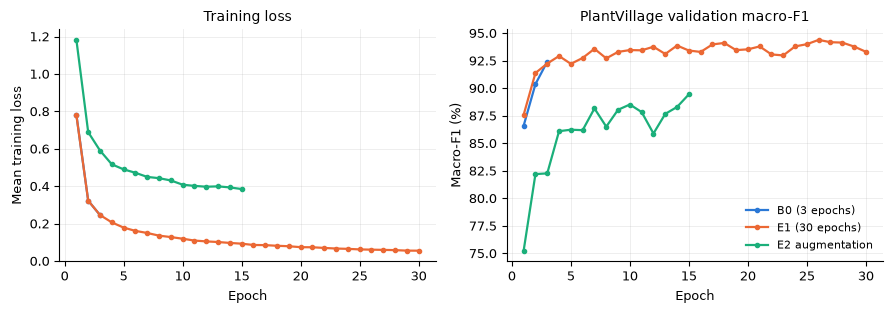

In [19]:
short = {c: c.split("___")[0].replace("Corn_(maize)", "Corn") + ": " +
         c.split("___")[1].replace("Cercospora_leaf_spot Gray_leaf_spot", "Gray leaf spot").replace("Tomato_mosaic_virus", "Mosaic virus").replace("_", " ")
         for c in class_names}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for log_df, name, col in [(pd.DataFrame(b0_log), "B0 (3 epochs)", SERIES[0]), (e1_log, "E1 (30 epochs)", SERIES[1]), (e2_log, "E2 augmentation", SERIES[2])]:
    axes[0].plot(log_df["epoch"], log_df["train_loss"], color=col, lw=1.6, marker="o", ms=3, label=name)
    axes[1].plot(log_df["epoch"], 100 * log_df["val_macro_f1"] if log_df["val_macro_f1"].max() <= 1 else log_df["val_macro_f1"],
                 color=col, lw=1.6, marker="o", ms=3, label=name)
axes[0].set(xlabel="Epoch", ylabel="Mean training loss", title="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Macro-F1 (%)", title="PlantVillage validation macro-F1")
for ax in axes: ax.grid(alpha=0.25, lw=0.6)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig(OUT / "fig_training_curves.png", dpi=200, bbox_inches="tight"); plt.show()

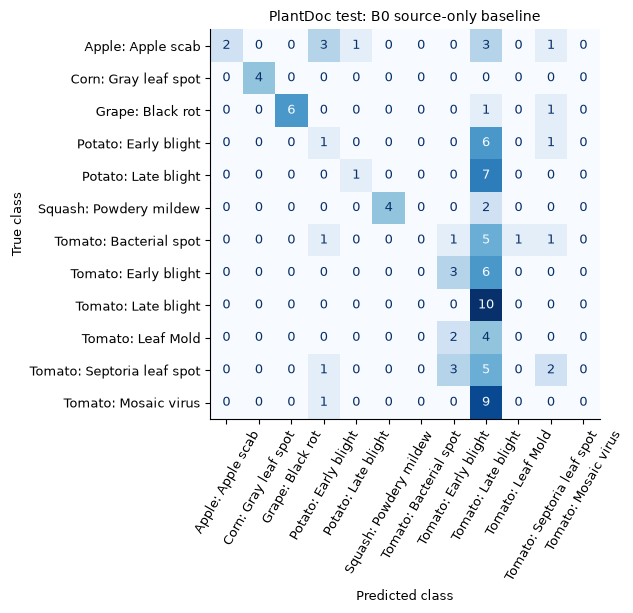

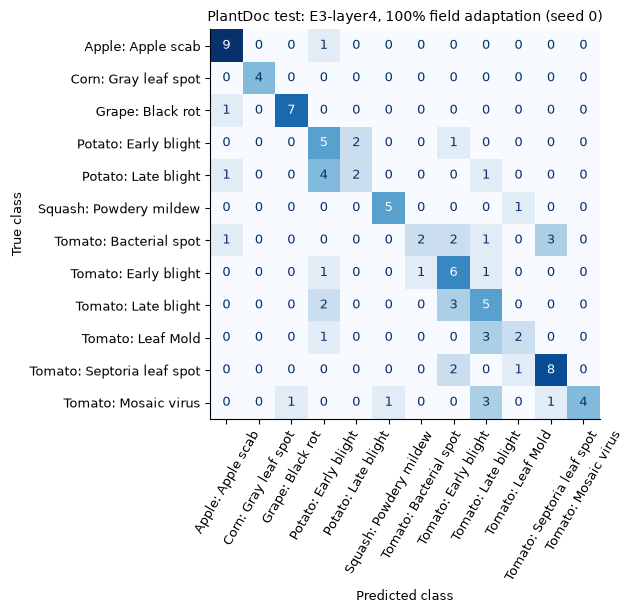

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
for key, fname, title in [("B0", "fig_confusion_baseline.png", "B0 source-only baseline"),
                          ("E3-layer4", "fig_confusion_finetuned.png", "E3-layer4, 100% field adaptation (seed 0)")]:
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    ConfusionMatrixDisplay.from_predictions(y_pd, predictions[(key, "PlantDoc test")], labels=range(len(class_names)),
                                            display_labels=[short[c] for c in class_names], xticks_rotation=60,
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"PlantDoc test: {title}"); ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    plt.tight_layout(); fig.savefig(OUT / fname, dpi=200, bbox_inches="tight"); plt.show()

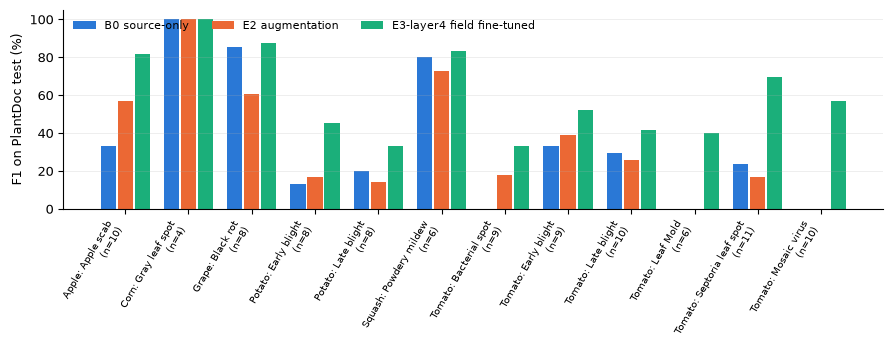

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.6))
xs = np.arange(len(class_names)); w = 0.27
for i, (key, name) in enumerate([("B0", "B0 source-only"), ("E2", "E2 augmentation"), ("E3-layer4", "E3-layer4 field fine-tuned")]):
    ax.bar(xs + (i - 1) * w, 100 * per_class[key], width=w - 0.03, color=SERIES[i], label=name)
ax.set_xticks(xs, [f"{short[c]}\n(n={n})" for c, n in zip(class_names, pc["Test images"])], rotation=60, ha="right", fontsize=7)
ax.set_ylabel("F1 on PlantDoc test (%)"); ax.set_ylim(0, 105); ax.grid(axis="y", alpha=0.25, lw=0.6)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
plt.tight_layout(); fig.savefig(OUT / "fig_perclass_f1.png", dpi=200, bbox_inches="tight"); plt.show()

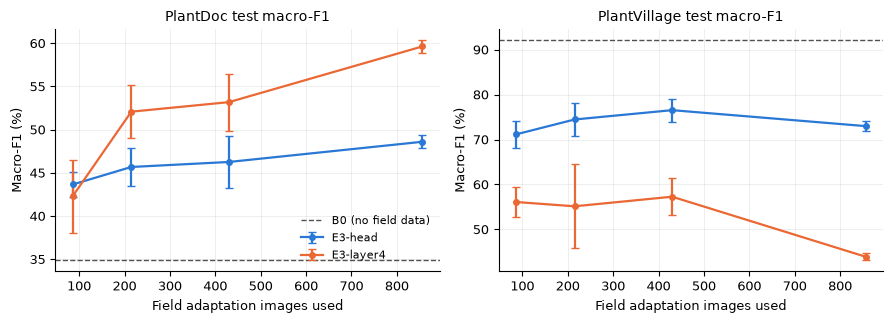

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharex=True)
for i, variant in enumerate(["E3-head", "E3-layer4"]):
    s = e3_summary[e3_summary["variant"] == variant]
    for ax, col, metric, title in [(axes[0], SERIES[i], "pd_test_f1", "PlantDoc test macro-F1"), (axes[1], SERIES[i], "pv_test_f1", "PlantVillage test macro-F1")]:
        ax.errorbar(s["images"], s[f"{metric}_mean"], yerr=s[f"{metric}_std"].fillna(0), color=col, lw=1.6, marker="o", ms=4, capsize=3, label=variant)
        ax.set_title(title)
for ax, key in [(axes[0], "PlantDoc test"), (axes[1], "PlantVillage test")]:
    ax.axhline(results[("B0", key)]["macro_f1"], color="#52514e", lw=1, ls="--", label="B0 (no field data)")
    ax.set(xlabel="Field adaptation images used", ylabel="Macro-F1 (%)"); ax.grid(alpha=0.25, lw=0.6)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig(OUT / "fig_field_fraction.png", dpi=200, bbox_inches="tight"); plt.show()

In [23]:
json.dump({"b0_epoch": b0_epoch, "b0_val_f1": best_f1, "e1_epoch": e1_epoch, "e2_epoch": e2_epoch,
           "field_pool": len(field_pool), "field_adapt": len(field_adapt), "field_val": len(field_val),
           "near_duplicate_files": n_near_files, "near_duplicate_pairs": len(near_pairs), "exact_overlap": exact_pairs,
           "plantdoc_train_files": n_train_files, "plantdoc_train_unique": n_unique, "device": str(fast), "smoke": SMOKE},
          open(OUT / "run_info.json", "w"), indent=2)
print("All outputs saved to", OUT)

All outputs saved to ~/Desktop/Plant_Disease_Domain_Gap/repo/outputs
